In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

# ---- 1. Load ----
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

# ---- 2. Fix TotalCharges (text -> number) ----
# Blank strings can't be converted, so they become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Safety check: only the 11 known blanks, and all must be tenure == 0
missing_mask = df["TotalCharges"].isna()
assert missing_mask.sum() == 11, "Unexpected number of missing TotalCharges"
assert (df.loc[missing_mask, "tenure"] == 0).all(), "Missing TotalCharges with tenure > 0"

# New customers (tenure 0) have not been billed yet -> 0 is the logical value
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# ---- 3. Remove duplicates (ignoring the unique ID) ----
n_before = len(df)
df = df.drop(columns="customerID")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicate rows. Clean shape: {df.shape}")
assert len(df) >= 1000

# ---- 4. Encode target ----
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
assert df["Churn"].isna().sum() == 0

# ---- 5. Features / target ----
X = df.drop(columns="Churn")
y = df["Churn"]

# ---- 6. Split FIRST, stratified so both sets keep the same churn rate ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

# ---- 7. Preprocessor (fitted later, inside a Pipeline, on training data only) ----
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

Raw shape: (7043, 21)
Removed 22 duplicate rows. Clean shape: (7021, 20)
Train: (5616, 19) | Test: (1405, 19)
Churn rate  train: 0.2644 | test: 0.2648


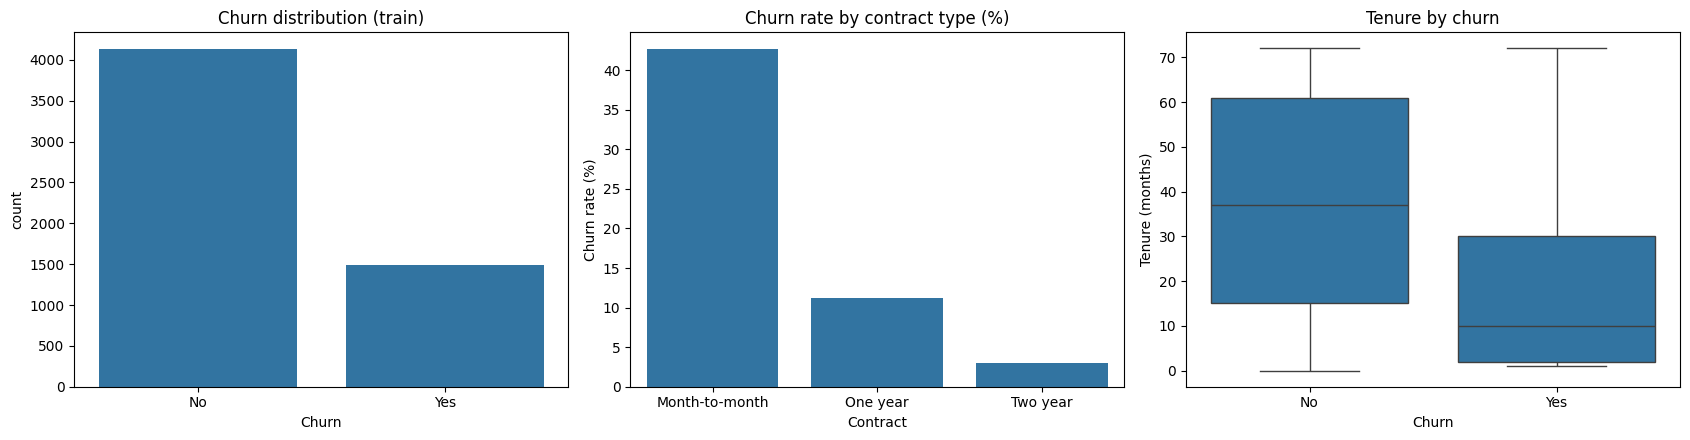

Contract
Month-to-month    42.7
One year          11.2
Two year           2.9
Name: Churn, dtype: float64
Churn
0    37.0
1    10.0
Name: tenure, dtype: float64


In [3]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../images", exist_ok=True)
os.makedirs("../results", exist_ok=True)

# EDA on TRAINING data only
eda = X_train.copy()
eda["Churn"] = y_train
churn_label = eda["Churn"].map({0: "No", 1: "Yes"})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Class balance
sns.countplot(x=churn_label, order=["No", "Yes"], ax=ax[0])
ax[0].set_title("Churn distribution (train)")
ax[0].set_xlabel("Churn")

# 2. Churn rate per contract type
rate = eda.groupby("Contract")["Churn"].mean().sort_values(ascending=False) * 100
sns.barplot(x=rate.index, y=rate.values, ax=ax[1])
ax[1].set_title("Churn rate by contract type (%)")
ax[1].set_ylabel("Churn rate (%)")

# 3. Tenure by churn
sns.boxplot(x=churn_label, y=eda["tenure"], order=["No", "Yes"], ax=ax[2])
ax[2].set_title("Tenure by churn")
ax[2].set_xlabel("Churn")
ax[2].set_ylabel("Tenure (months)")

plt.tight_layout()
plt.savefig("../images/eda_overview.png", dpi=150)
plt.show()

print(rate.round(1))
print(eda.groupby("Churn")["tenure"].median())

,Model,Train time (s),Accuracy,Precision,Recall,F1
0,Dummy (majority class),0.074,0.7352,0.0000,0.0000,0.0000
1,Logistic Regression,0.182,0.8021,0.6610,0.5188,0.5813
2,Decision Tree,0.167,0.7139,0.4634,0.5108,0.4859
3,Random Forest,2.546,0.7751,0.5993,0.4543,0.5168
4,KNN,0.059,0.7594,0.5512,0.4919,0.5199
5,SVM (RBF),1.595,0.7979,0.6618,0.4839,0.5590


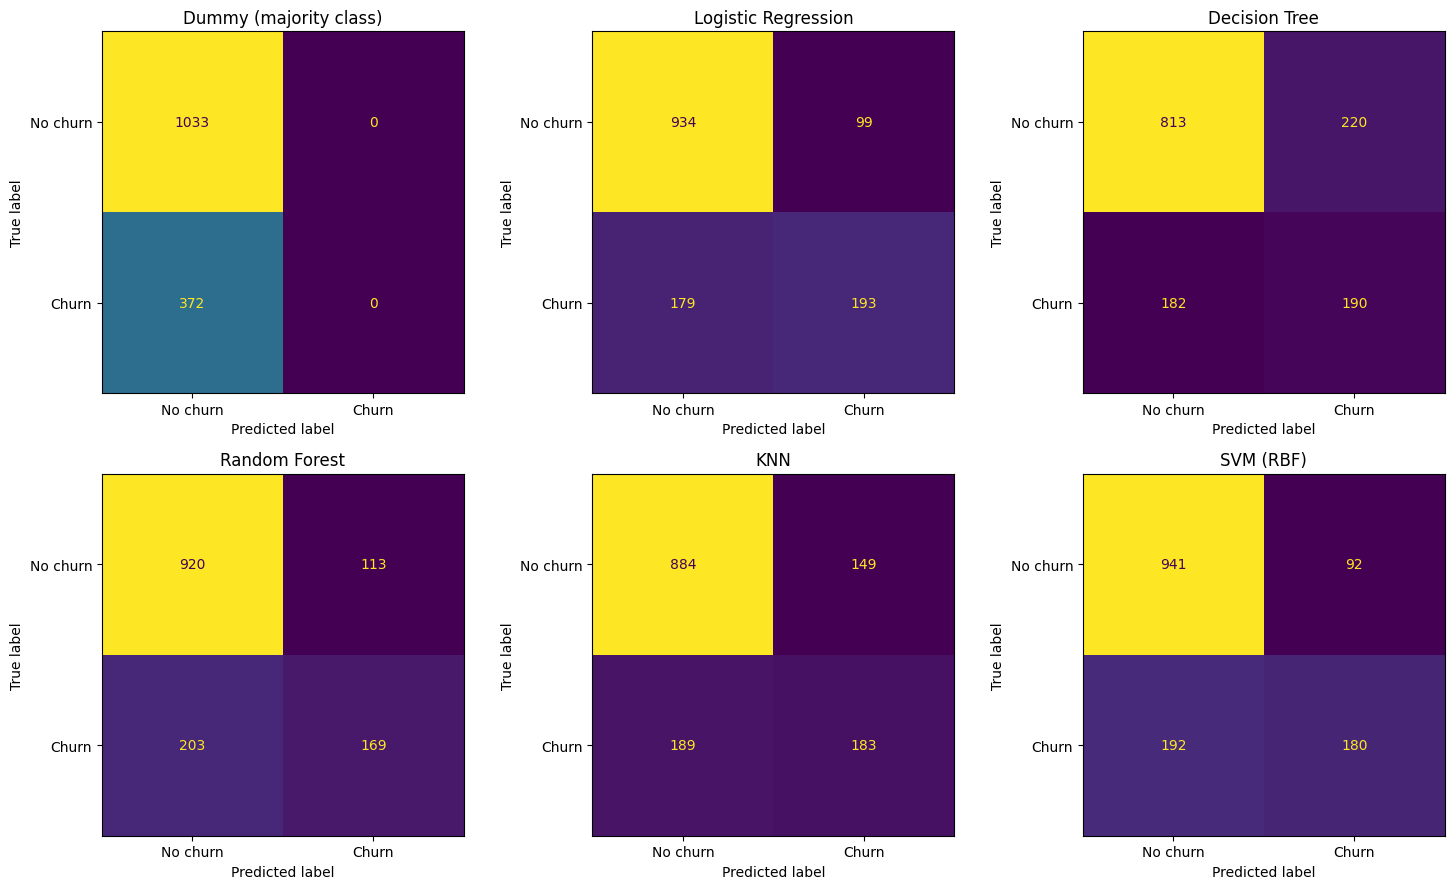

In [4]:
import time
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

models = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE),
}

rows, conf_mats = [], {}
for name, model in models.items():
    # Pipeline = preprocessing + model, so scaling/encoding is fitted on train data only
    pipe = Pipeline([("prep", preprocessor), ("model", model)])

    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - start      # measured, not estimated

    preds = pipe.predict(X_test)                  # same test set for every model
    rows.append({
        "Model": name,
        "Train time (s)": round(train_time, 3),
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
    })
    conf_mats[name] = confusion_matrix(y_test, preds)

baseline_results = pd.DataFrame(rows).round(4)
baseline_results.to_csv("../results/baseline_classification_results.csv", index=False)
display(baseline_results)

# Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, cm) in zip(axes.ravel(), conf_mats.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../images/baseline_confusion_matrices.png", dpi=150)
plt.show()

In [5]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 7, 10],
         "model__min_samples_leaf": [1, 10, 30],
         "model__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [5, 10, None],
         "model__min_samples_leaf": [1, 5, 10],
         "model__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [5, 11, 21, 31],
         "model__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        SVC(random_state=RANDOM_STATE),
        {"model__C": [0.1, 1, 10],
         "model__gamma": ["scale", 0.01],
         "model__class_weight": [None, "balanced"]}),
}

tuned_rows, tuned_conf_mats, best_models = [], {}, {}
for name, (estimator, grid) in search_space.items():
    # "model__" prefix = parameter belongs to the "model" step of the pipeline
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)

    start = time.perf_counter()
    gs.fit(X_train, y_train)                 # search uses TRAIN data only
    search_time = time.perf_counter() - start

    preds = gs.predict(X_test)               # test set used once, after tuning
    tuned_rows.append({
        "Model": name,
        "Search time (s)": round(search_time, 1),
        "Final fit time (s)": round(gs.refit_time_, 3),
        "CV F1 (train)": gs.best_score_,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "Best params": str(gs.best_params_),
    })
    tuned_conf_mats[name] = confusion_matrix(y_test, preds)
    best_models[name] = gs.best_estimator_
    print(f"{name}: done in {search_time:.1f}s -> {gs.best_params_}")

tuned_results = pd.DataFrame(tuned_rows).round(4)
tuned_results.to_csv("../results/tuned_classification_results.csv", index=False)
display(tuned_results)

Logistic Regression: done in 5.3s -> {'model__C': 10, 'model__class_weight': 'balanced'}
Decision Tree: done in 9.2s -> {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 30}
Random Forest: done in 173.8s -> {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}
KNN: done in 3.5s -> {'model__n_neighbors': 31, 'model__weights': 'uniform'}
SVM (RBF): done in 74.1s -> {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 'scale'}


,Model,Search time (s),Final fit time (s),CV F1 (train),Accuracy,Precision,Recall,F1,Best params
0,Logistic Regression,5.3,0.102,0.6299,0.7381,0.5035,0.7823,0.6126,"{'model__C': 10, 'model__class_weight': 'balan..."
1,Decision Tree,9.2,0.066,0.6256,0.7423,0.5091,0.7527,0.6074,"{'model__class_weight': 'balanced', 'model__ma..."
2,Random Forest,173.8,2.287,0.6397,0.7658,0.5416,0.7527,0.6299,"{'model__class_weight': 'balanced', 'model__ma..."
3,KNN,3.5,0.032,0.6056,0.7872,0.6137,0.5296,0.5685,"{'model__n_neighbors': 31, 'model__weights': '..."
4,SVM (RBF),74.1,1.720,0.6242,0.7601,0.5325,0.7715,0.6301,"{'model__C': 1, 'model__class_weight': 'balanc..."


,Model,Stage,Fit time (s),Accuracy,Precision,Recall,F1
0,Decision Tree,Baseline,0.167,0.7139,0.4634,0.5108,0.4859
1,Decision Tree,Tuned,0.066,0.7423,0.5091,0.7527,0.6074
2,KNN,Baseline,0.059,0.7594,0.5512,0.4919,0.5199
3,KNN,Tuned,0.032,0.7872,0.6137,0.5296,0.5685
4,Logistic Regression,Baseline,0.182,0.8021,0.6610,0.5188,0.5813
5,Logistic Regression,Tuned,0.102,0.7381,0.5035,0.7823,0.6126
6,Random Forest,Baseline,2.546,0.7751,0.5993,0.4543,0.5168
7,Random Forest,Tuned,2.287,0.7658,0.5416,0.7527,0.6299
8,SVM (RBF),Baseline,1.595,0.7979,0.6618,0.4839,0.5590
9,SVM (RBF),Tuned,1.720,0.7601,0.5325,0.7715,0.6301


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,-0.0640,-0.1575,0.2635,0.0313
Decision Tree,0.0284,0.0457,0.2419,0.1215
Random Forest,-0.0093,-0.0577,0.2984,0.1131
KNN,0.0278,0.0625,0.0377,0.0486
SVM (RBF),-0.0378,-0.1293,0.2876,0.0711


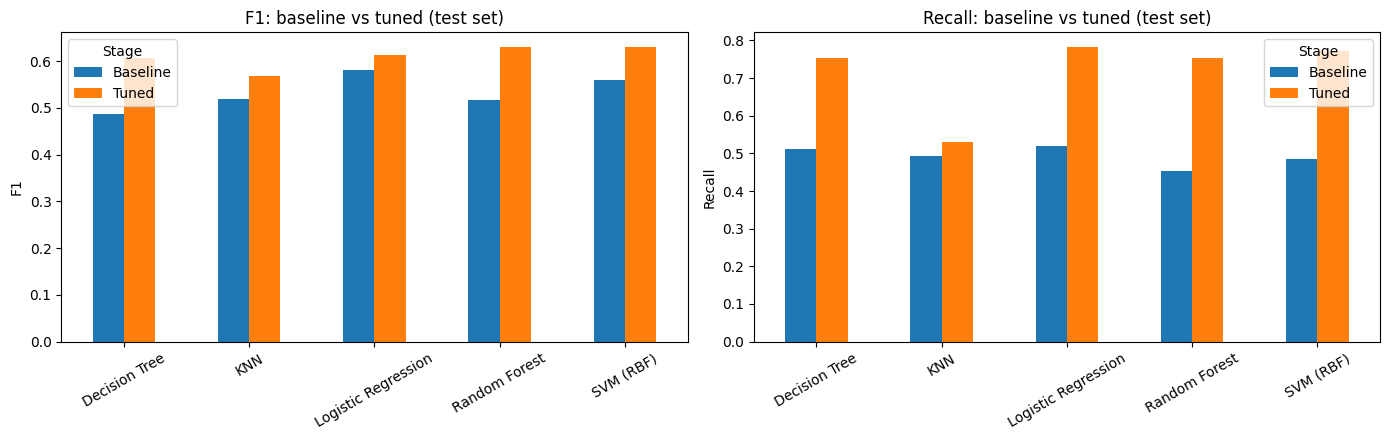

In [6]:
base = baseline_results[baseline_results["Model"] != "Dummy (majority class)"].copy()
base["Stage"] = "Baseline"
base = base.rename(columns={"Train time (s)": "Fit time (s)"})

tuned = tuned_results.rename(columns={"Final fit time (s)": "Fit time (s)"}).copy()
tuned["Stage"] = "Tuned"

cols = ["Model", "Stage", "Fit time (s)", "Accuracy", "Precision", "Recall", "F1"]
comparison = (pd.concat([base[cols], tuned[cols]])
              .sort_values(["Model", "Stage"]).reset_index(drop=True).round(4))
comparison.to_csv("../results/before_after_comparison.csv", index=False)
display(comparison)

# Change from baseline to tuned (positive = improved)
metrics = ["Accuracy", "Precision", "Recall", "F1"]
change = (tuned.set_index("Model")[metrics] - base.set_index("Model")[metrics]).round(4)
display(change)

# Plot F1 and Recall, before vs after
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["F1", "Recall"]):
    pv = comparison.pivot(index="Model", columns="Stage", values=metric)[["Baseline", "Tuned"]]
    pv.plot(kind="bar", ax=ax)
    ax.set_title(f"{metric}: baseline vs tuned (test set)")
    ax.set_ylabel(metric); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../images/before_after_f1_recall.png", dpi=150)
plt.show()

In [7]:
from sklearn.base import clone

def median_fit_time(pipe, n_runs=5):
    times = []
    for _ in range(n_runs):
        p = clone(pipe)
        if "n_jobs" in p.named_steps["model"].get_params():
            p.set_params(model__n_jobs=1)          # same CPU usage for every model
        start = time.perf_counter()
        p.fit(X_train, y_train)
        times.append(time.perf_counter() - start)
    return round(float(np.median(times)), 3)

timing = {}
for name in best_models:
    base_pipe = Pipeline([("prep", preprocessor), ("model", models[name])])
    timing[name] = {"Baseline": median_fit_time(base_pipe),
                    "Tuned": median_fit_time(best_models[name])}

# Replace the old, unfair times in the comparison table
for name, t in timing.items():
    for stage in ["Baseline", "Tuned"]:
        mask = (comparison["Model"] == name) & (comparison["Stage"] == stage)
        comparison.loc[mask, "Fit time (s)"] = t[stage]

comparison.to_csv("../results/before_after_comparison.csv", index=False)
display(comparison)

,Model,Stage,Fit time (s),Accuracy,Precision,Recall,F1
0,Decision Tree,Baseline,0.119,0.7139,0.4634,0.5108,0.4859
1,Decision Tree,Tuned,0.082,0.7423,0.5091,0.7527,0.6074
2,KNN,Baseline,0.059,0.7594,0.5512,0.4919,0.5199
3,KNN,Tuned,0.055,0.7872,0.6137,0.5296,0.5685
4,Logistic Regression,Baseline,0.077,0.8021,0.6610,0.5188,0.5813
5,Logistic Regression,Tuned,0.114,0.7381,0.5035,0.7823,0.6126
6,Random Forest,Baseline,0.834,0.7751,0.5993,0.4543,0.5168
7,Random Forest,Tuned,1.632,0.7658,0.5416,0.7527,0.6299
8,SVM (RBF),Baseline,1.329,0.7979,0.6618,0.4839,0.5590
9,SVM (RBF),Tuned,1.737,0.7601,0.5325,0.7715,0.6301


In [8]:
# ---- Task B: regression on MonthlyCharges ----
X_reg = df.drop(columns=["MonthlyCharges", "TotalCharges", "Churn"])
y_reg = df["MonthlyCharges"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", Xr_train.shape, "| Test:", Xr_test.shape)
print(yr_train.describe().round(2))

reg_numeric = ["tenure"]
reg_categorical = [c for c in X_reg.columns if c not in reg_numeric]
reg_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), reg_numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), reg_categorical),
])

# Validation: does price really depend on the services?
print(df.groupby("InternetService")["MonthlyCharges"].agg(["count", "mean", "std", "min", "max"]).round(2))

Train: (5616, 17) | Test: (1405, 17)
count    5616.00
mean       64.83
std        30.17
min        18.25
25%        35.50
50%        70.30
75%        90.10
max       118.75
Name: MonthlyCharges, dtype: float64
                 count   mean    std    min     max
InternetService                                    
DSL               2419  58.11  16.26  23.45   94.80
Fiber optic       3090  91.54  12.64  67.75  118.75
No                1512  21.09   2.17  18.25   26.90


,Model,Train time (s),MAE,MSE,RMSE,R2
0,Dummy (mean),0.033,25.7137,880.8155,29.6785,-0.0000
1,Linear Regression,0.056,0.7997,1.1061,1.0517,0.9987
2,Decision Tree,0.108,1.2426,2.8300,1.6823,0.9968
3,Random Forest,2.819,1.0069,1.8373,1.3555,0.9979
4,KNN,0.034,2.7637,17.7300,4.2107,0.9799
5,SVR (RBF),2.297,1.0294,1.8587,1.3633,0.9979


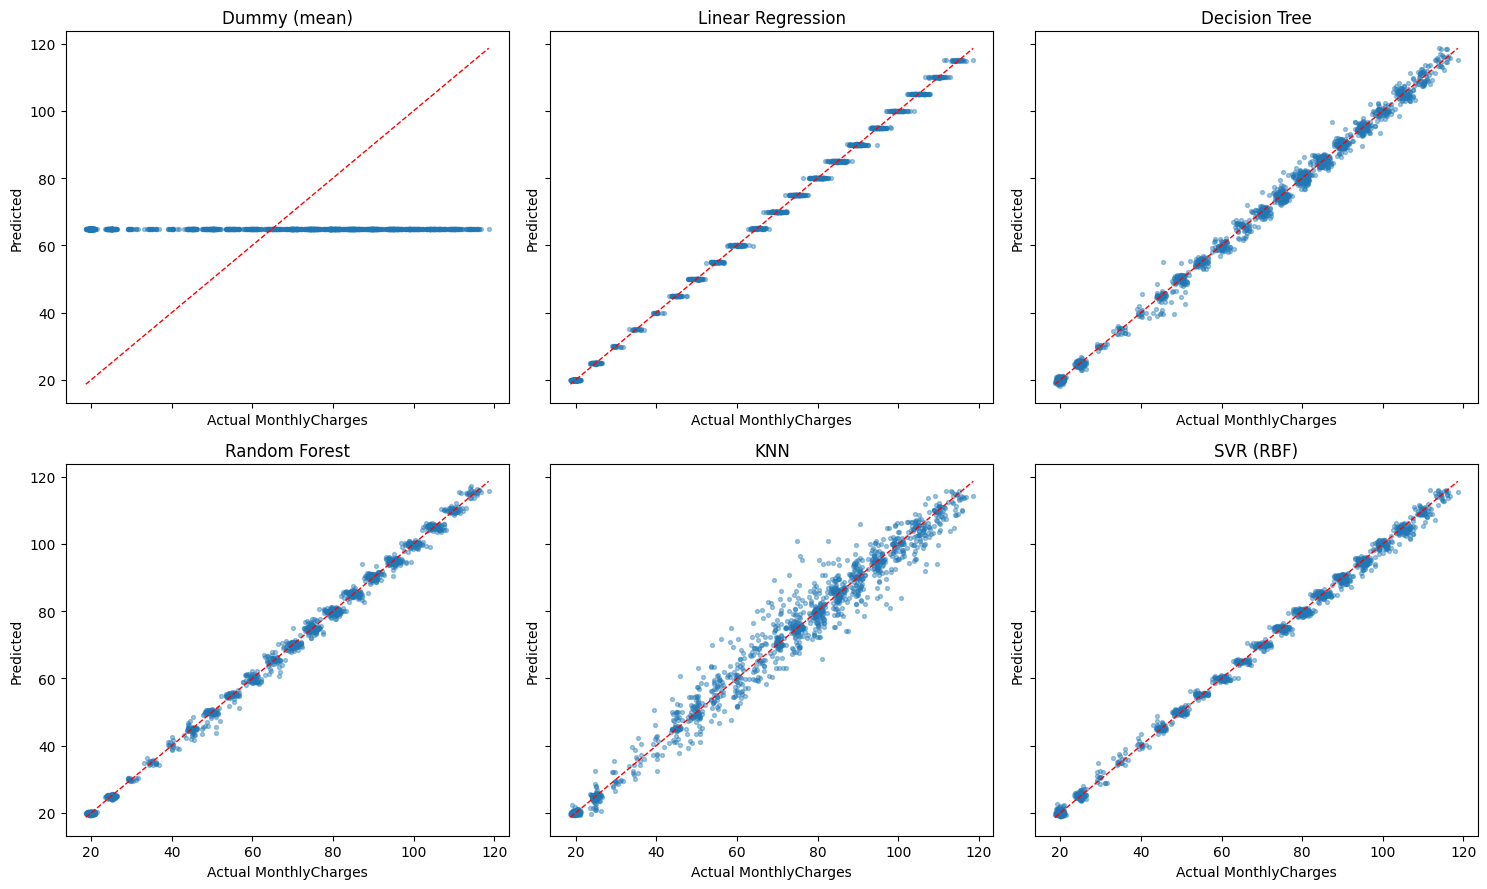

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "KNN": KNeighborsRegressor(),
    "SVR (RBF)": SVR(),
}

rows, preds_store = [], {}
for name, model in reg_models.items():
    pipe = Pipeline([("prep", reg_preprocessor), ("model", model)])

    start = time.perf_counter()
    pipe.fit(Xr_train, yr_train)
    train_time = time.perf_counter() - start

    preds = pipe.predict(Xr_test)
    mse = mean_squared_error(yr_test, preds)
    rows.append({
        "Model": name,
        "Train time (s)": round(train_time, 3),
        "MAE": mean_absolute_error(yr_test, preds),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),     # RMSE = square root of MSE
        "R2": r2_score(yr_test, preds),
    })
    preds_store[name] = preds

reg_baseline_results = pd.DataFrame(rows).round(4)
reg_baseline_results.to_csv("../results/baseline_regression_results.csv", index=False)
display(reg_baseline_results)

# Actual vs predicted: points near the red line = good predictions
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
lims = [yr_test.min(), yr_test.max()]
for ax, (name, preds) in zip(axes.ravel(), preds_store.items()):
    ax.scatter(yr_test, preds, s=8, alpha=0.4)
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual MonthlyCharges")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.savefig("../images/regression_actual_vs_predicted.png", dpi=150)
plt.show()

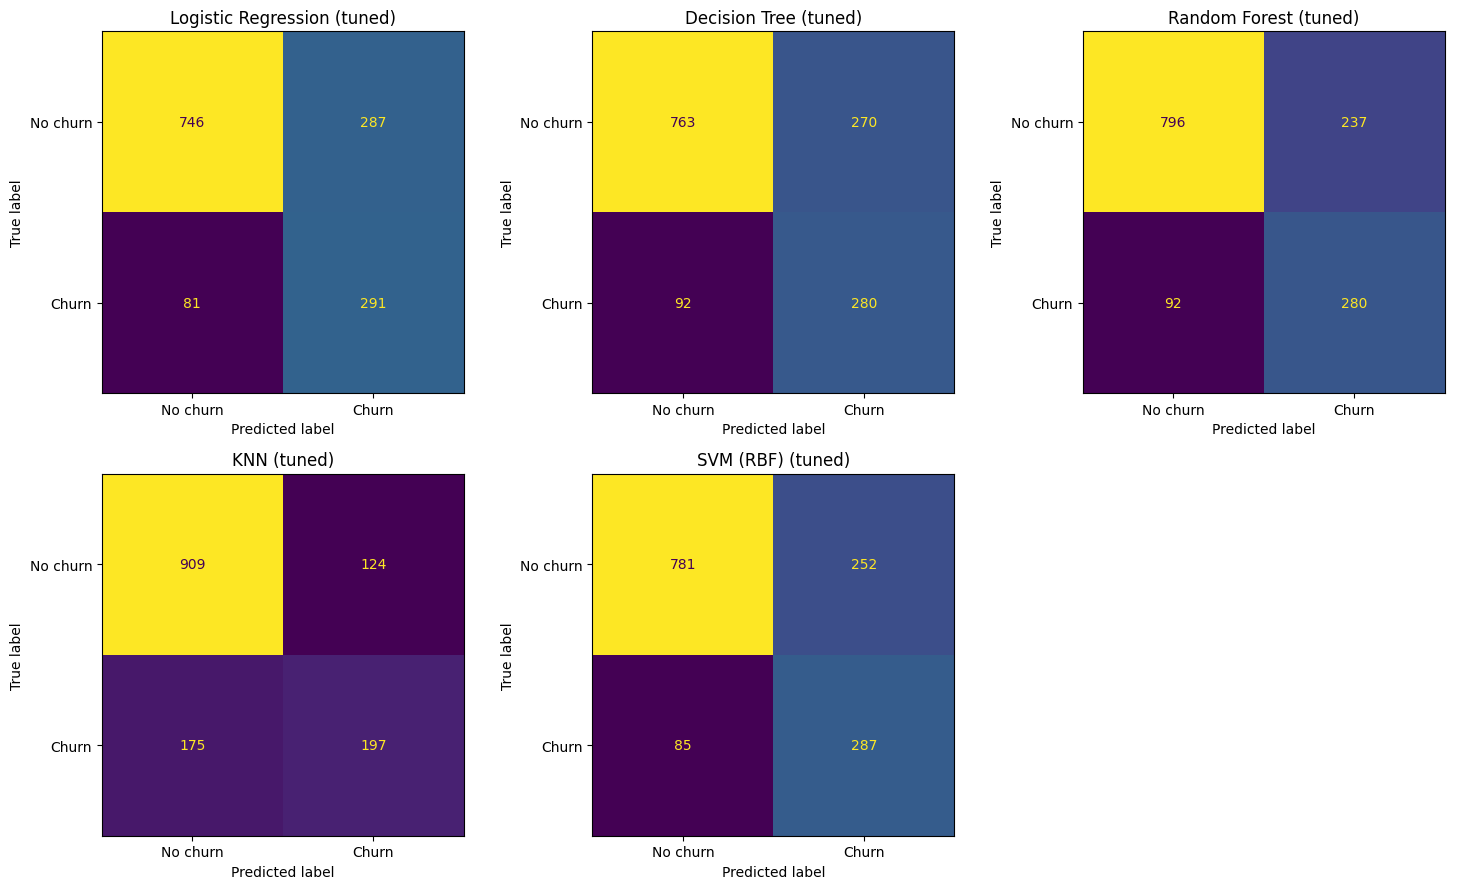

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, cm) in zip(axes.ravel(), tuned_conf_mats.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name} (tuned)")
axes.ravel()[-1].axis("off")          # 5 models, 6 slots
plt.tight_layout()
plt.savefig("../images/tuned_confusion_matrices.png", dpi=150)
plt.show()

,0
Contract_Month-to-month,0.1402
tenure,0.1208
TotalCharges,0.0961
OnlineSecurity_No,0.0670
Contract_Two year,0.0664
TechSupport_No,0.0576
MonthlyCharges,0.0568
InternetService_Fiber optic,0.0562
PaymentMethod_Electronic check,0.0359
Contract_One year,0.0230


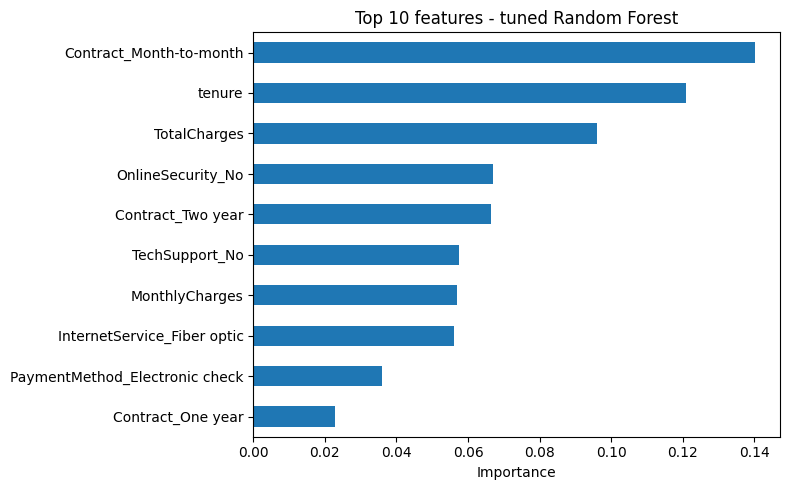

In [11]:
rf_pipe = best_models["Random Forest"]
names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
importances = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
top10 = importances.sort_values(ascending=False).head(10)
display(top10.round(4))

top10.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 features - tuned Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../images/rf_feature_importance.png", dpi=150)
plt.show()

In [12]:
clf_notes = {
    "Logistic Regression": ("Fastest to train, simple, easy to explain; highest recall after tuning (0.7823)",
                            "Assumes straight-line effects; tuned accuracy (0.7381) is barely above the 'always No' accuracy (0.7352)"),
    "Decision Tree":       ("Easy to visualise and explain",
                            "Unpruned baseline overfits (lowest baseline F1); needs depth limits"),
    "Random Forest":       ("Handles non-linear effects, gives feature importance; best CV F1 (0.6397)",
                            "Longest search (173.8s), slower to train, harder to explain"),
    "KNN":                 ("Simple, no training step, quick to fit",
                            "No class_weight option, so recall stayed low (0.5296); sensitive to scaling and many one-hot columns"),
    "SVM (RBF)":           ("Handles non-linear boundaries; tied for best F1 (0.6301)",
                            "Slow search (74.1s), no built-in feature importance"),
}
reg_notes = {
    "Dummy (mean)":      ("Reference point only", "Ignores all features"),
    "Linear Regression": ("Fast, simple, best on every metric here", "Assumes additive effects; would miss complex interactions"),
    "Decision Tree":     ("Easy to explain, no scaling needed", "Coarse predictions (steps); lower R2 than the top models"),
    "Random Forest":     ("Handles non-linear effects, stable", "Slower than Linear Regression with no accuracy gain here"),
    "KNN":               ("Simple, no assumptions about shape", "Worst R2 and MAE here; distance gets noisy with many one-hot columns"),
    "SVR (RBF)":         ("Flexible, accurate (R2 0.9979)", "Slower; needs scaled inputs; hard to interpret"),
}

# Classification table
search_time = tuned_results.set_index("Model")["Search time (s)"]
final_clf = comparison.copy()
final_clf["Search time (s)"] = np.where(final_clf["Stage"] == "Tuned",
                                        final_clf["Model"].map(search_time), np.nan)
final_clf["Advantages"] = final_clf["Model"].map(lambda m: clf_notes[m][0])
final_clf["Limitations"] = final_clf["Model"].map(lambda m: clf_notes[m][1])
final_clf.to_csv("../results/final_classification_comparison.csv", index=False)
display(final_clf)

# Regression table
final_reg = reg_baseline_results.copy()
final_reg["Advantages"] = final_reg["Model"].map(lambda m: reg_notes[m][0])
final_reg["Limitations"] = final_reg["Model"].map(lambda m: reg_notes[m][1])
final_reg.to_csv("../results/final_regression_comparison.csv", index=False)
display(final_reg)

,Model,Stage,Fit time (s),Accuracy,Precision,Recall,F1,Search time (s),Advantages,Limitations
0,Decision Tree,Baseline,0.119,0.7139,0.4634,0.5108,0.4859,NaN,Easy to visualise and explain,Unpruned baseline overfits (lowest baseline F1...
1,Decision Tree,Tuned,0.082,0.7423,0.5091,0.7527,0.6074,9.2,Easy to visualise and explain,Unpruned baseline overfits (lowest baseline F1...
2,KNN,Baseline,0.059,0.7594,0.5512,0.4919,0.5199,NaN,"Simple, no training step, quick to fit","No class_weight option, so recall stayed low (..."
3,KNN,Tuned,0.055,0.7872,0.6137,0.5296,0.5685,3.5,"Simple, no training step, quick to fit","No class_weight option, so recall stayed low (..."
4,Logistic Regression,Baseline,0.077,0.8021,0.6610,0.5188,0.5813,NaN,"Fastest to train, simple, easy to explain; hig...",Assumes straight-line effects; tuned accuracy ...
5,Logistic Regression,Tuned,0.114,0.7381,0.5035,0.7823,0.6126,5.3,"Fastest to train, simple, easy to explain; hig...",Assumes straight-line effects; tuned accuracy ...
6,Random Forest,Baseline,0.834,0.7751,0.5993,0.4543,0.5168,NaN,"Handles non-linear effects, gives feature impo...","Longest search (173.8s), slower to train, hard..."
7,Random Forest,Tuned,1.632,0.7658,0.5416,0.7527,0.6299,173.8,"Handles non-linear effects, gives feature impo...","Longest search (173.8s), slower to train, hard..."
8,SVM (RBF),Baseline,1.329,0.7979,0.6618,0.4839,0.5590,NaN,Handles non-linear boundaries; tied for best F...,"Slow search (74.1s), no built-in feature impor..."
9,SVM (RBF),Tuned,1.737,0.7601,0.5325,0.7715,0.6301,74.1,Handles non-linear boundaries; tied for best F...,"Slow search (74.1s), no built-in feature impor..."


,Model,Train time (s),MAE,MSE,RMSE,R2,Advantages,Limitations
0,Dummy (mean),0.033,25.7137,880.8155,29.6785,-0.0000,Reference point only,Ignores all features
1,Linear Regression,0.056,0.7997,1.1061,1.0517,0.9987,"Fast, simple, best on every metric here",Assumes additive effects; would miss complex i...
2,Decision Tree,0.108,1.2426,2.8300,1.6823,0.9968,"Easy to explain, no scaling needed",Coarse predictions (steps); lower R2 than the ...
3,Random Forest,2.819,1.0069,1.8373,1.3555,0.9979,"Handles non-linear effects, stable",Slower than Linear Regression with no accuracy...
4,KNN,0.034,2.7637,17.7300,4.2107,0.9799,"Simple, no assumptions about shape",Worst R2 and MAE here; distance gets noisy wit...
5,SVR (RBF),2.297,1.0294,1.8587,1.3633,0.9979,"Flexible, accurate (R2 0.9979)",Slower; needs scaled inputs; hard to interpret
